# KAN option pricing — single-asset, cross-asset and multi-asset training

Extends the NIFTY-only KAN notebook to the full training-regime study from Goswami, Rajani &
Tanksale (2021), using Kolmogorov-Arnold Networks in place of the ANN/XGBoost pair.

| Regime | What it does | Paper |
|---|---|---|
| **Single-asset** | Train and test on the same asset (NIFTY50, BANKNIFTY) | Tables 4, 5 |
| **Cross-asset** | Train on asset A, test on asset B without retraining | Table 8 |
| **Multi-asset (combined)** | Train on pooled data, test on each asset out of sample | Table 9 |
| Benchmark | Black-Scholes with 20-day historical volatility | B-S rows |
| Diagnostics | Band coverage, actual-vs-predicted bias | Figs. 11, 14 |

**One thing that had to change for cross-asset work to be valid.** In the original notebook the bin
cutoff (and therefore `NUM_CLASSES`) was derived from NIFTY alone. If each asset gets its own
binning, bin 12 means a different price on each asset and the regimes are not comparable. Here the
cutoff is computed **once on the pooled data** and applied to both assets, which is the paper's
requirement: *"Without uniform binning, it would not be possible to combine or compare models
trained on different datasets."*

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install pykan -q

In [3]:
import warnings, os, math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.stats import norm
from kan import KAN

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device:", device)

device: cuda


## 0. Configuration

In [4]:
DATA_DIR = '/content/drive/MyDrive/data_files/2021-2026'
BOND_FILE = f"{DATA_DIR}/bond_yield.csv"

ASSET_FILES = {
    'NIFTY50': {
        'options': f"{DATA_DIR}/Nifty2021-2026.csv",
        'spot':    f"{DATA_DIR}/Nifty_Spot.csv",
    },
    'BANKNIFTY': {
        'options': f"{DATA_DIR}/banknifty2021-2026.csv",
        'spot':    f"{DATA_DIR}/BankNifty_Spot.csv",
    },
}

# ---- filtering / binning (paper values) --------------------------------
LOOKBACK   = 20
DTE_MIN, DTE_MAX = 3, 45
ATM_BAND   = 0.04
W_BIN      = 0.1        # bin width on the 100*C/K scale
BIN_COVER  = 98.0       # percentile of pooled data below the overflow bin
TRAIN_FRAC = 0.70
OPTION_TYPE = 'CE'
SEED = 42

# Approach II: the original notebook kept only mu_C and commented out mu_O/mu_H/mu_L.
# False reproduces that choice (14 features); True gives the paper's 17.
USE_ALL_OHLC_MEANS = True

# ---- KAN hyperparameters ----------------------------------------------
KAN_HIDDEN   = [32, 16]
KAN_GRID, KAN_K = 5, 3
KAN_LR, KAN_LAMB = 1e-3, 1e-4
CHUNK_STEPS  = 5        # steps between validation checks
MAX_STEPS    = 8000
PATIENCE     = 5
BATCH        = 4096     # clamped below the val-set size automatically; -1 = full batch
PRED_CHUNK   = 2048     # forward-pass chunk size, keeps KAN activation memory bounded

QUICK_MODE = False      # True -> MAX_STEPS=200, for a fast end-to-end dry run
if QUICK_MODE:
    MAX_STEPS = 200

print("Assets:", list(ASSET_FILES))

Assets: ['NIFTY50', 'BANKNIFTY']


## 1. Data pipeline (per asset)

The original linear cleaning code, refactored into a function so it runs once per asset. Logic is
unchanged: calls only, traded rows only, 3-45 DTE, near-ATM, previous-day close required, 20 days of
underlying OHLC history, bond yield attached.

In [5]:
def load_bond_yields(path):
    bonds = pd.read_csv(path)
    bonds.columns = ['date', 'risk_free_rate', 'rf_open', 'rf_high', 'rf_low', 'change_pct']
    bonds['date'] = pd.to_datetime(bonds['date'], errors='coerce')
    for c in ['risk_free_rate', 'rf_open', 'rf_high', 'rf_low']:
        bonds[c] = pd.to_numeric(bonds[c].astype(str).str.replace(',', ''), errors='coerce')
    bonds.loc[bonds['risk_free_rate'] > 50, 'risk_free_rate'] = np.nan   # sentinel prints
    bonds = bonds.dropna(subset=['date']).sort_values('date')
    bonds['risk_free_rate'] = bonds['risk_free_rate'].ffill().bfill()
    full = pd.date_range(bonds['date'].min(), bonds['date'].max(), freq='D')
    return (bonds.set_index('date')[['risk_free_rate']]
                 .reindex(full).rename_axis('date').ffill().reset_index())


def load_spot(path):
    spot = pd.read_csv(path)
    spot.columns = ['date', 'spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']
    spot['date'] = pd.to_datetime(spot['date'], errors='coerce')
    for c in ['spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']:
        spot[c] = pd.to_numeric(spot[c].astype(str).str.replace(',', ''), errors='coerce')
    return spot.dropna(subset=['date']).sort_values('date').reset_index(drop=True)


def load_options(path):
    opt = pd.read_csv(path).drop(columns=['Unnamed: 0'], errors='ignore')
    opt.columns = ['symbol', 'date', 'expiry', 'option_type', 'strike',
                   'open', 'high', 'low', 'close', 'ltp', 'settle_price',
                   'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
                   'open_interest', 'change_in_oi', 'underlying']
    opt['date'] = pd.to_datetime(opt['date'], format='%d-%b-%Y', errors='coerce')
    opt['expiry'] = pd.to_datetime(opt['expiry'], format='%d-%b-%Y', errors='coerce')
    for c in ['strike', 'open', 'high', 'low', 'close', 'ltp', 'settle_price', 'contracts',
              'turnover_lakhs', 'premium_turnover_lakhs', 'open_interest', 'change_in_oi',
              'underlying']:
        opt[c] = pd.to_numeric(opt[c].astype(str).str.replace(',', ''), errors='coerce')
    opt['option_type'] = opt['option_type'].str.strip().str.upper()
    return opt.dropna(subset=['date', 'expiry', 'strike'])


def build_lookback_frame(spot, lookback=LOOKBACK):
    lb = spot[['date', 'spot_open', 'spot_high', 'spot_low', 'spot_close']].copy()
    for lag in range(1, lookback + 1):
        lb[f'und_open_lag{lag}']  = lb['spot_open'].shift(lag)
        lb[f'und_high_lag{lag}']  = lb['spot_high'].shift(lag)
        lb[f'und_low_lag{lag}']   = lb['spot_low'].shift(lag)
        lb[f'und_close_lag{lag}'] = lb['spot_close'].shift(lag)
    return (lb.drop(columns=['spot_open', 'spot_high', 'spot_low', 'spot_close'])
              .dropna().reset_index(drop=True))


def build_asset_dataset(name, files, bonds, verbose=True):
    counts = {}
    opt = load_options(files['options'])
    counts['raw'] = len(opt)
    spot = load_spot(files['spot'])

    opt = opt.merge(spot[['date', 'spot_close']], on='date', how='left')
    opt['underlying'] = opt['spot_close']
    opt = opt.drop(columns=['spot_close']).dropna(subset=['underlying'])

    if OPTION_TYPE is not None:
        opt = opt[opt['option_type'] == OPTION_TYPE]
    opt = opt[(opt['contracts'].fillna(0) > 0) & (opt['turnover_lakhs'].fillna(0) > 0)]

    opt['days_to_expiry'] = (opt['expiry'] - opt['date']).dt.days
    opt = opt[(opt['days_to_expiry'] >= DTE_MIN) & (opt['days_to_expiry'] <= DTE_MAX)]

    opt['moneyness_gap'] = (1 - opt['underlying'] / opt['strike']).abs()
    opt = opt[opt['moneyness_gap'] <= ATM_BAND]

    opt = opt.sort_values(['expiry', 'option_type', 'strike', 'date'])
    opt['prev_day_close'] = opt.groupby(['expiry', 'option_type', 'strike'])['close'].shift(1)
    opt = opt.dropna(subset=['prev_day_close'])

    opt = opt.merge(build_lookback_frame(spot), on='date', how='inner')
    opt = opt.merge(spot, on='date', how='left')
    opt = opt.merge(bonds, on='date', how='left')
    opt['risk_free_rate'] = opt['risk_free_rate'].ffill().bfill()
    opt['time_to_maturity_yrs'] = opt['days_to_expiry'] / 365.0
    opt['asset'] = name

    opt = opt.sort_values('date').reset_index(drop=True)
    counts['filtered'] = len(opt)
    if verbose:
        print(f"[{name}] raw={counts['raw']:,}  filtered={counts['filtered']:,}  "
              f"({opt['date'].min().date()} to {opt['date'].max().date()})")
    return opt, counts

In [6]:
bonds = load_bond_yields(BOND_FILE)

DATA, COUNTS = {}, {}
for name, files in ASSET_FILES.items():
    DATA[name], COUNTS[name] = build_asset_dataset(name, files, bonds)

ASSETS = list(DATA)
MULTI_ASSET = len(ASSETS) >= 2
print("\nassets loaded:", ASSETS, "| multi-asset regimes enabled:", MULTI_ASSET)

[NIFTY50] raw=708,909  filtered=126,566  (2021-01-04 to 2026-07-07)
[BANKNIFTY] raw=656,347  filtered=95,238  (2021-01-04 to 2026-06-25)

assets loaded: ['NIFTY50', 'BANKNIFTY'] | multi-asset regimes enabled: True


## 2. Shared binning across assets

The cutoff bin is found on the **pooled** 100·C/K distribution, so a bin index carries the same
meaning for both assets. This is what makes cross-asset and combined training meaningful.

In [7]:
pooled_ratio = pd.concat([100 * d['close'] / d['strike'] for d in DATA.values()], ignore_index=True)
pooled_raw = np.ceil(pooled_ratio / W_BIN).astype(int).clip(lower=1)

counts_sorted = pooled_raw.value_counts().sort_index()
cum_pct = counts_sorted.cumsum() / counts_sorted.sum() * 100
CUTOFF_BIN = int(cum_pct[cum_pct <= BIN_COVER].index.max())
NUM_CLASSES = CUTOFF_BIN + 1
BIN_WIDTH = W_BIN

print(f"Pooled data: bins 1-{CUTOFF_BIN} cover ~{BIN_COVER}%  ->  NUM_CLASSES = {NUM_CLASSES}")

for name, d in DATA.items():
    d['output_ratio'] = 100 * d['close'] / d['strike']
    d['bin_label_raw'] = np.ceil(d['output_ratio'] / W_BIN).astype(int).clip(lower=1)
    d['bin_label'] = np.where(d['bin_label_raw'] > CUTOFF_BIN, NUM_CLASSES, d['bin_label_raw'])
    share = 100 * (d['bin_label'] == NUM_CLASSES).mean()
    print(f"[{name}] bins {d['bin_label'].min()}-{d['bin_label'].max()}, "
          f"overflow bin holds {share:.2f}% of rows")

Pooled data: bins 1-44 cover ~98.0%  ->  NUM_CLASSES = 45
[NIFTY50] bins 1-45, overflow bin holds 1.53% of rows
[BANKNIFTY] bins 1-45, overflow bin holds 3.57% of rows


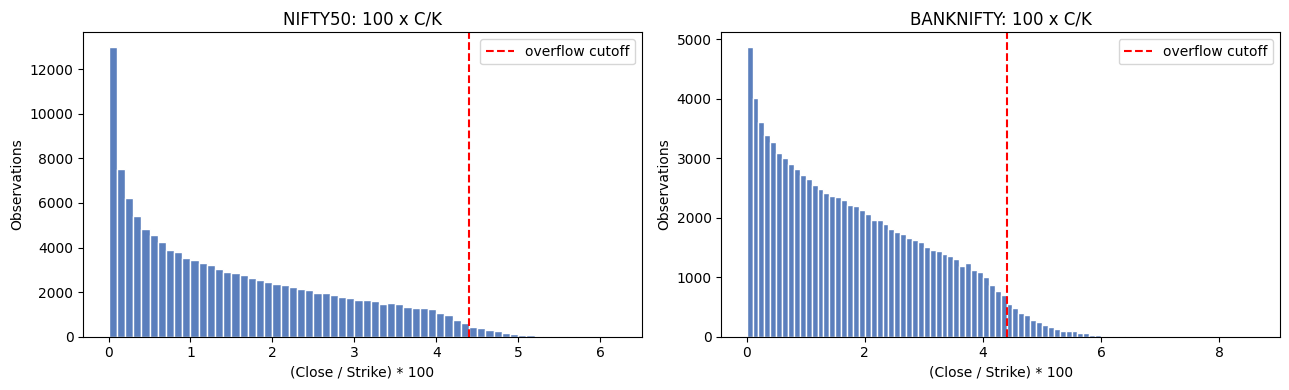

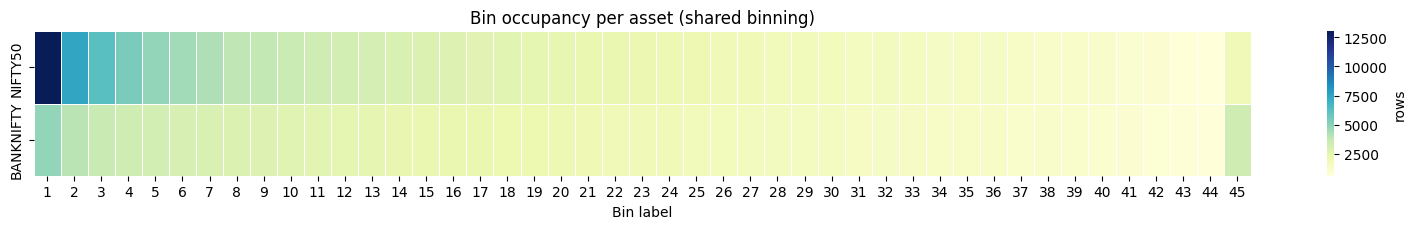

In [8]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6.5*len(DATA), 4), squeeze=False)
for ax, (name, d) in zip(axes[0], DATA.items()):
    ax.hist(d['output_ratio'], bins=np.arange(0, d['output_ratio'].max()+W_BIN, W_BIN),
            color='#5b7fbd', edgecolor='white')
    ax.axvline(CUTOFF_BIN * W_BIN, color='red', ls='--', label='overflow cutoff')
    ax.set_xlabel('(Close / Strike) * 100'); ax.set_ylabel('Observations')
    ax.set_title(f'{name}: 100 x C/K'); ax.legend()
plt.tight_layout(); plt.show()

# per-bin occupancy on the pooled scale
occ = pd.DataFrame({name: d['bin_label'].value_counts().reindex(range(1, NUM_CLASSES+1), fill_value=0)
                    for name, d in DATA.items()})
plt.figure(figsize=(max(12, NUM_CLASSES*0.35), 2.4))
sns.heatmap(occ.T, cmap='YlGnBu', linewidths=0.4, cbar_kws={'label': 'rows'})
plt.title('Bin occupancy per asset (shared binning)'); plt.xlabel('Bin label')
plt.tight_layout(); plt.show()

## 3. Feature sets — Approaches I, II, III

Identical column names and ordering for every asset, which is what lets a model trained on one asset
be fed another asset's matrix directly.

In [9]:
def log_returns_from_lookback(df, field, lookback=LOOKBACK):
    cols_chrono = [f'und_{field}_lag{i}' for i in range(lookback, 0, -1)]
    return np.diff(np.log(df[cols_chrono].values.astype(float)), axis=1)


def signed_sqrt(x):
    out = np.zeros_like(x)
    m = x != 0
    out[m] = x[m] / np.sqrt(np.abs(x[m]))
    return out


def contract_block(df):
    return pd.DataFrame({
        'moneyness':        (df['underlying'] / df['strike']).values,
        'time_to_maturity': df['days_to_expiry'].values.astype(float),
        'interest_rate':    df['risk_free_rate'].values.astype(float),
    }, index=df.index)


def build_approach1(df):
    os_close = np.sort(log_returns_from_lookback(df, 'close'), axis=1)
    X = pd.DataFrame(os_close, columns=[f'os_close_{i+1}' for i in range(os_close.shape[1])],
                     index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach2(df):
    lr_o = log_returns_from_lookback(df, 'open')
    lr_h = log_returns_from_lookback(df, 'high')
    lr_l = log_returns_from_lookback(df, 'low')
    lr_c = log_returns_from_lookback(df, 'close')

    stack = np.stack([lr_o, lr_h, lr_l, lr_c], axis=1)
    centered = stack - stack.mean(axis=2, keepdims=True)
    cov = np.einsum('nik,njk->nij', centered, centered) / (stack.shape[2] - 1)
    cov_t = signed_sqrt(cov)

    labels = ['O', 'H', 'L', 'C']
    cov_cols = {f'cov_{labels[i]}{labels[j]}': cov_t[:, i, j]
                for i in range(4) for j in range(i + 1)}

    means = ({'mu_O': lr_o.mean(axis=1), 'mu_H': lr_h.mean(axis=1),
              'mu_L': lr_l.mean(axis=1), 'mu_C': lr_c.mean(axis=1)}
             if USE_ALL_OHLC_MEANS else {'mu_C': lr_c.mean(axis=1)})

    X = pd.DataFrame({**means, **cov_cols}, index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach3(df):
    X = build_approach2(df).drop(columns=['bin_label'])
    X['prev_option_price_scaled'] = (df['prev_day_close'] / df['strike']).values
    lookback_close_cols = [f'und_close_lag{i}' for i in range(1, LOOKBACK + 1)]
    X['mean_moneyness'] = (df[lookback_close_cols].mean(axis=1) / df['strike']).values
    X['bin_label'] = df['bin_label'].values
    return X


APPROACH_BUILDERS = {'Approach I': build_approach1,
                     'Approach II': build_approach2,
                     'Approach III': build_approach3}
APPROACHES = list(APPROACH_BUILDERS)

In [10]:
FEATURES = {name: {ap: fn(d) for ap, fn in APPROACH_BUILDERS.items()}
            for name, d in DATA.items()}

print("Feature counts (excl. label):")
print(pd.DataFrame({ap: {n: FEATURES[n][ap].shape[1]-1 for n in FEATURES} for ap in APPROACHES}))

# columns must line up across assets or cross-asset scoring is meaningless
for ap in APPROACHES:
    cols = [list(FEATURES[n][ap].columns) for n in ASSETS]
    assert all(c == cols[0] for c in cols), f"column mismatch in {ap}"
print("\nColumn alignment across assets: OK")

Feature counts (excl. label):
           Approach I  Approach II  Approach III
NIFTY50            22           17            19
BANKNIFTY          22           17            19

Column alignment across assets: OK


## 4. Train / test split and metrics

Split is linear in time per asset (the paper's 70:30 on unique trading dates).

In [11]:
SPLIT = {}
for name, d in DATA.items():
    dates = np.sort(d['date'].unique())
    cutoff = dates[int(len(dates) * TRAIN_FRAC) - 1]
    SPLIT[name] = {'train': (d['date'] <= cutoff).values,
                   'test':  (d['date'] > cutoff).values,
                   'cutoff': pd.Timestamp(cutoff)}
    COUNTS[name].update(train=int(SPLIT[name]['train'].sum()),
                        test=int(SPLIT[name]['test'].sum()))
    print(f"[{name}] cutoff {pd.Timestamp(cutoff).date()} | "
          f"train {COUNTS[name]['train']:,} | test {COUNTS[name]['test']:,}")

print()
print(pd.DataFrame(COUNTS).loc[['raw', 'filtered', 'train', 'test']])

[NIFTY50] cutoff 2024-11-11 | train 79,485 | test 47,081
[BANKNIFTY] cutoff 2024-11-07 | train 76,505 | test 18,733

          NIFTY50  BANKNIFTY
raw        708909     656347
filtered   126566      95238
train       79485      76505
test        47081      18733


In [12]:
def em_metric(actual, pred, bin_width=W_BIN):
    # Eq. (5)
    return bin_width * np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)))

def rho_metric(actual, pred):
    # Eq. (6)
    return np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)) > 2)

def acc_metric(actual, pred):
    # Eq. (4)
    return np.mean(np.round(np.asarray(pred, float)) == np.asarray(actual, float))

def split_xy(feat_df, mask):
    cols = [c for c in feat_df.columns if c != 'bin_label']
    return (feat_df.loc[mask, cols].values.astype(np.float64),
            feat_df.loc[mask, 'bin_label'].values.astype(np.int64),
            cols)

## 5. KAN training and scoring

`fit_kan` returns a bundle holding the model plus the **training set's** mean and std. Cross-asset
scoring reuses the source bundle's scaler, which is the honest thing to do — the target asset's
statistics are not available at training time.

Two practical guards: `batch` is clamped below the validation-set size (pykan samples a test batch
of the same size, and errors out if it exceeds the set), and predictions run in chunks because KAN
stores per-sample activations.

In [13]:
def standardize_fit(X):
    mean = X.mean(axis=0, keepdims=True)
    std = X.std(axis=0, keepdims=True)
    std[std < 1e-8] = 1e-8
    return mean, std


def split_val(X, y, frac=0.1, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.permutation(X.shape[0])
    n_val = max(1, int(X.shape[0] * frac))
    return X[idx[n_val:]], y[idx[n_val:]], X[idx[:n_val]], y[idx[:n_val]]


def fit_kan(X_train_full, y_train_full, num_classes=None, hidden=KAN_HIDDEN,
            seed=SEED, verbose=False, tag=""):
    num_classes = num_classes or NUM_CLASSES
    X_tr_raw, y_tr, X_val_raw, y_val = split_val(X_train_full, y_train_full, 0.1, seed)

    mean, std = standardize_fit(X_tr_raw)
    X_tr = (X_tr_raw - mean) / std
    X_val = (X_val_raw - mean) / std

    dataset = {
        'train_input': torch.tensor(X_tr, dtype=torch.float32).to(device),
        'train_label': torch.tensor(y_tr - 1, dtype=torch.long).to(device),
        'test_input':  torch.tensor(X_val, dtype=torch.float32).to(device),
        'test_label':  torch.tensor(y_val - 1, dtype=torch.long).to(device),
    }

    width = [X_tr.shape[1]] + list(hidden) + [num_classes]
    model = KAN(width=width, grid=KAN_GRID, k=KAN_K, seed=seed, device=device, auto_save=False)
    model.saveckpt = lambda *a, **k: None
    loss_fn = torch.nn.CrossEntropyLoss()

    # pykan draws a validation batch of the same size, so keep batch <= both sets
    batch = -1 if BATCH == -1 else int(min(BATCH, len(y_tr), len(y_val)))

    best_loss, best_state, bad = float('inf'), None, 0
    for i in range(MAX_STEPS // CHUNK_STEPS):
        model.fit(dataset, opt='Adam', lr=KAN_LR, steps=CHUNK_STEPS, lamb=KAN_LAMB,
                  loss_fn=loss_fn, update_grid=(i < 3), batch=batch)
        with torch.no_grad():
            val_loss = loss_fn(model(dataset['test_input']), dataset['test_label']).item()
        if verbose:
            print(f"    {tag} step {(i+1)*CHUNK_STEPS:4d}  val_loss {val_loss:.4f}")
        if val_loss < best_loss - 1e-4:
            best_loss, best_state, bad = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return {'model': model, 'mean': mean, 'std': std, 'num_classes': num_classes,
            'width': width, 'val_loss': best_loss,
            'steps_run': (i + 1) * CHUNK_STEPS}


@torch.no_grad()
def predict_bins(bundle, X_raw, chunk=PRED_CHUNK):
    Xs = (X_raw - bundle['mean']) / bundle['std']
    out = []
    for s in range(0, len(Xs), chunk):
        xb = torch.tensor(Xs[s:s+chunk], dtype=torch.float32).to(device)
        out.append(torch.argmax(bundle['model'](xb), dim=1).cpu().numpy())
    return np.concatenate(out) + 1


def score(bundle, X_raw, y_true):
    pred = predict_bins(bundle, X_raw)
    return pred, {'EM': em_metric(y_true, pred), 'rho': rho_metric(y_true, pred),
                  'A': acc_metric(y_true, pred)}

## Experiment 1 — Single-asset training (Tables 4 and 5)

One KAN per (asset, approach), trained and tested on the same asset. Bundles are kept in
`SINGLE_BUNDLES` and reused by Experiments 2 and 3 — no retraining.

In [14]:
SINGLE_BUNDLES, SINGLE_PRED = {}, {}
rows = []

for name in ASSETS:
    for ap in APPROACHES:
        X_tr, y_tr, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
        X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])

        print(f"training KAN: {name} / {ap}  (features={X_tr.shape[1]}, train={len(y_tr):,})")
        b = fit_kan(X_tr, y_tr, tag=f"{name}/{ap}")
        b['columns'] = cols
        SINGLE_BUNDLES[(name, ap)] = b

        pred, m = score(b, X_te, y_te)
        SINGLE_PRED[(name, ap)] = {'y_true': y_te, 'pred': pred}
        rows.append({'asset': name, 'approach': ap, **m,
                     'steps': b['steps_run'], 'val_loss': b['val_loss']})
        print(f"   EM {m['EM']:.4f} | rho {m['rho']:.4f} | A {m['A']:.4f}")

single_results = pd.DataFrame(rows).set_index(['asset', 'approach']).round(4)
print("\n=== Tables 4 / 5: single-asset KAN ===")
print(single_results)

training KAN: NIFTY50 / Approach I  (features=22, train=79,485)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:01<00:00,  3.38it/s
| train_loss: 1.95e+00 | test_loss: 1.94e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 12.37it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 11.65it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 26.24it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 24.71it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 28.10it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 28.49it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 26.12it/s
| train_loss: 1.91e+00 | test_loss: 1.90e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 29.31it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.16e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.1616 | rho 0.2245 | A 0.2706
training KAN: NIFTY50 / Approach II  (features=17, train=79,485)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00,  9.22it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 13.31it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 13.16it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 31.28it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 31.05it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 32.01it/s
| train_loss: 1.92e+00 | test_loss: 1.91e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 30.80it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.16e+02 | : 100%|█| 5/5 [00:00<00:00, 31.88it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 31.62it/s
| train_loss: 1.89e+00 | test_loss: 1.89e+00 | reg: 1.25e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.1731 | rho 0.2433 | A 0.2818
training KAN: NIFTY50 / Approach III  (features=19, train=79,485)


...

   EM 0.3190 | rho 0.4602 | A 0.1564
training KAN: BANKNIFTY / Approach II  (features=17, train=76,505)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 10.14it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 13.01it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 13.36it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.10e+02 | : 100%|█| 5/5 [00:00<00:00, 29.91it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.14e+02 | : 100%|█| 5/5 [00:00<00:00, 28.87it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.18e+02 | : 100%|█| 5/5 [00:00<00:00, 27.77it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 28.13it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.24e+02 | : 100%|█| 5/5 [00:00<00:00, 27.01it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.28e+02 | : 100%|█| 5/5 [00:00<00:00, 25.60it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.31e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.2295 | rho 0.3118 | A 0.2322
training KAN: BANKNIFTY / Approach III  (features=19, train=76,505)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.16e+02 | : 100%|█| 5/5 [00:00<00:00,  9.61it/s
| train_loss: 1.95e+00 | test_loss: 1.94e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 12.73it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.14e+02 | : 100%|█| 5/5 [00:00<00:00, 12.81it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.15e+02 | : 100%|█| 5/5 [00:00<00:00, 30.98it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.19e+02 | : 100%|█| 5/5 [00:00<00:00, 30.80it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.22e+02 | : 100%|█| 5/5 [00:00<00:00, 30.63it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.24e+02 | : 100%|█| 5/5 [00:00<00:00, 30.55it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.28e+02 | : 100%|█| 5/5 [00:00<00:00, 30.88it/s
| train_loss: 1.89e+00 | test_loss: 1.89e+00 | reg: 1.31e+02 | : 100%|█| 5/5 [00:00<00:00, 30.75it/s
| train_loss: 1.88e+00 | test_loss: 1.88e+00 | reg: 1.34e+02 | : 100%|█| 5/5 [00:00<00:00, 

   EM 0.2046 | rho 0.2641 | A 0.2640

=== Tables 4 / 5: single-asset KAN ===
                            EM     rho       A  steps  val_loss
asset     approach                                             
NIFTY50   Approach I    0.1616  0.2245  0.2706    920    1.6297
          Approach II   0.1731  0.2433  0.2818    640    1.6600
          Approach III  0.1435  0.1815  0.3336    765    1.4816
BANKNIFTY Approach I    0.3190  0.4602  0.1564   1250    1.6236
          Approach II   0.2295  0.3118  0.2322    910    1.7320
          Approach III  0.2046  0.2641  0.2640    910    1.5591


## Experiment 2 — Black-Scholes benchmark

Same test rows, priced with Black-Scholes using 20-day historical volatility, then mapped onto the
same shared bin scale. This is the "B-S pricing" row the trained models have to beat.

In [15]:
def black_scholes_call(S, K, T, r, sigma):
    S, K, T = np.asarray(S, float), np.asarray(K, float), np.asarray(T, float)
    r, sigma = np.asarray(r, float), np.asarray(sigma, float)
    T = np.clip(T, 1/365, None); sigma = np.clip(sigma, 1e-4, None)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


def price_to_bin(price, strike):
    ratio = 100 * np.asarray(price, float) / np.asarray(strike, float)
    return np.clip(np.ceil(ratio / W_BIN), 1, NUM_CLASSES).astype(int)


BS = {}
for name, d in DATA.items():
    d['hist_vol'] = log_returns_from_lookback(d, 'close').std(axis=1, ddof=1) * np.sqrt(252)
    sub = d.loc[SPLIT[name]['test']].copy()
    sub['bs_price'] = black_scholes_call(sub['underlying'], sub['strike'],
                                         sub['time_to_maturity_yrs'],
                                         sub['risk_free_rate']/100, sub['hist_vol'])
    bs_bin = price_to_bin(sub['bs_price'], sub['strike'])
    actual = np.clip(sub['bin_label'].values, 1, NUM_CLASSES)
    BS[name] = {'EM': em_metric(actual, bs_bin), 'rho': rho_metric(actual, bs_bin),
                'A': acc_metric(actual, bs_bin), 'frame': sub}
    print(f"[{name}] B-S -> EM {BS[name]['EM']:.4f} | rho {BS[name]['rho']:.4f}")

bs_table = pd.DataFrame({k: {m: v[m] for m in ('EM', 'rho', 'A')} for k, v in BS.items()}).T.round(4)
print("\n=== Black-Scholes benchmark ===")
print(bs_table)

[NIFTY50] B-S -> EM 0.2185 | rho 0.3322
[BANKNIFTY] B-S -> EM 0.3011 | rho 0.4568

=== Black-Scholes benchmark ===
               EM     rho       A
NIFTY50    0.2185  0.3322  0.2221
BANKNIFTY  0.3011  0.4568  0.1527


## Experiment 3 — Cross-asset training and testing (Table 8)

Each single-asset model is applied to the *other* asset's test set, unchanged. Because the I/O is
scale free (order statistics of log returns, moneyness, 100·C/K), this is a legitimate transfer.
The paper's finding to check: a model trained on the other asset can beat the one trained on the
target asset itself.

In [16]:
cross_rows = []
if MULTI_ASSET:
    for src in ASSETS:
        for tgt in ASSETS:
            if src == tgt:
                continue
            for ap in APPROACHES:
                X_te, y_te, _ = split_xy(FEATURES[tgt][ap], SPLIT[tgt]['test'])
                _, m = score(SINGLE_BUNDLES[(src, ap)], X_te, y_te)
                cross_rows.append({'trained_on': src, 'tested_on': tgt, 'approach': ap, **m})

    cross_results = (pd.DataFrame(cross_rows)
                     .set_index(['trained_on', 'tested_on', 'approach']).round(4))
    print("=== Table 8: cross-asset transfer ===")
    print(cross_results)

    print("\nSame-asset baseline on the same test sets:")
    print(single_results[['EM', 'rho']])

    print("\nCross minus same-asset EM (negative = the foreign model is better):")
    for r in cross_rows:
        base = single_results.loc[(r['tested_on'], r['approach']), 'EM']
        print(f"  {r['trained_on']:>10} -> {r['tested_on']:<10} {r['approach']:<13} "
              f"{r['EM']:.4f} vs {base:.4f}   delta {r['EM']-base:+.4f}")
else:
    print("Skipped: needs two assets in ASSET_FILES.")

=== Table 8: cross-asset transfer ===
                                       EM     rho       A
trained_on tested_on approach                            
NIFTY50    BANKNIFTY Approach I    0.2219  0.3387  0.2214
                     Approach II   0.2075  0.2991  0.2422
                     Approach III  0.1688  0.2291  0.2666
BANKNIFTY  NIFTY50   Approach I    0.2736  0.4283  0.1751
                     Approach II   0.1983  0.2739  0.2428
                     Approach III  0.1862  0.2576  0.2549

Same-asset baseline on the same test sets:
                            EM     rho
asset     approach                    
NIFTY50   Approach I    0.1616  0.2245
          Approach II   0.1731  0.2433
          Approach III  0.1435  0.1815
BANKNIFTY Approach I    0.3190  0.4602
          Approach II   0.2295  0.3118
          Approach III  0.2046  0.2641

Cross minus same-asset EM (negative = the foreign model is better):
     NIFTY50 -> BANKNIFTY  Approach I    0.2219 vs 0.3190   delta -0.0971

## Experiment 4 — Multi-asset combined training (Table 9)

One KAN per approach, trained on the **pooled** training rows of both assets, then tested out of
sample on each asset separately. The paper's central claim is that this beats single-asset training
on both assets at once.

In [17]:
COMBINED_BUNDLES, combined_rows = {}, []

if MULTI_ASSET:
    for ap in APPROACHES:
        X_parts, y_parts = [], []
        for name in ASSETS:
            Xa, ya, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
            X_parts.append(Xa); y_parts.append(ya)
        X_tr = np.vstack(X_parts); y_tr = np.concatenate(y_parts)

        print(f"training COMBINED KAN: {ap}  (train rows {len(y_tr):,})")
        b = fit_kan(X_tr, y_tr, tag=f"COMBINED/{ap}")
        b['columns'] = cols
        COMBINED_BUNDLES[ap] = b

        for name in ASSETS:
            X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])
            pred, m = score(b, X_te, y_te)
            SINGLE_PRED[('COMBINED', ap, name)] = {'y_true': y_te, 'pred': pred}
            combined_rows.append({'approach': ap, 'test_asset': name, **m})
            print(f"   tested on {name:<10} EM {m['EM']:.4f} | rho {m['rho']:.4f}")

        # pooled test set as well
        Xp = np.vstack([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[0] for n in ASSETS])
        yp = np.concatenate([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[1] for n in ASSETS])
        _, m = score(b, Xp, yp)
        combined_rows.append({'approach': ap, 'test_asset': 'POOLED', **m})

    combined_results = (pd.DataFrame(combined_rows)
                        .set_index(['approach', 'test_asset']).round(4))
    print("\n=== Table 9: combined (multi-asset) training ===")
    print(combined_results)
else:
    print("Skipped: needs two assets in ASSET_FILES.")

training COMBINED KAN: Approach I  (train rows 155,990)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.09e+02 | : 100%|█| 5/5 [00:00<00:00,  8.95it/s
| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 10.84it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 10.74it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.02e+02 | : 100%|█| 5/5 [00:00<00:00, 24.29it/s
| train_loss: 1.94e+00 | test_loss: 1.93e+00 | reg: 1.04e+02 | : 100%|█| 5/5 [00:00<00:00, 25.73it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.06e+02 | : 100%|█| 5/5 [00:00<00:00, 24.49it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 28.58it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 28.65it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.14e+02 | : 100%|█| 5/5 [00:00<00:00, 28.88it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.17e+02 | : 100%|█| 5/5 [00:00<00:00, 

   tested on NIFTY50    EM 0.2189 | rho 0.3120
   tested on BANKNIFTY  EM 0.2548 | rho 0.3429
training COMBINED KAN: Approach II  (train rows 155,990)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.09e+02 | : 100%|█| 5/5 [00:00<00:00, 10.01it/s
| train_loss: 1.95e+00 | test_loss: 1.94e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 12.85it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.07e+02 | : 100%|█| 5/5 [00:00<00:00, 11.40it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.08e+02 | : 100%|█| 5/5 [00:00<00:00, 28.00it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.11e+02 | : 100%|█| 5/5 [00:00<00:00, 26.74it/s
| train_loss: 1.93e+00 | test_loss: 1.92e+00 | reg: 1.14e+02 | : 100%|█| 5/5 [00:00<00:00, 25.92it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.17e+02 | : 100%|█| 5/5 [00:00<00:00, 24.38it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 24.04it/s
| train_loss: 1.91e+00 | test_loss: 1.90e+00 | reg: 1.24e+02 | : 100%|█| 5/5 [00:00<00:00, 28.86it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.26e+02 | : 100%|█| 5/5 [00:00<00:00, 

   tested on NIFTY50    EM 0.1694 | rho 0.2253
   tested on BANKNIFTY  EM 0.2168 | rho 0.2910
training COMBINED KAN: Approach III  (train rows 155,990)


| train_loss: 1.95e+00 | test_loss: 1.95e+00 | reg: 1.17e+02 | : 100%|█| 5/5 [00:00<00:00,  9.24it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 11.44it/s
| train_loss: 1.94e+00 | test_loss: 1.94e+00 | reg: 1.12e+02 | : 100%|█| 5/5 [00:00<00:00, 11.08it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.13e+02 | : 100%|█| 5/5 [00:00<00:00, 25.12it/s
| train_loss: 1.93e+00 | test_loss: 1.93e+00 | reg: 1.16e+02 | : 100%|█| 5/5 [00:00<00:00, 25.79it/s
| train_loss: 1.92e+00 | test_loss: 1.92e+00 | reg: 1.20e+02 | : 100%|█| 5/5 [00:00<00:00, 23.59it/s
| train_loss: 1.91e+00 | test_loss: 1.91e+00 | reg: 1.24e+02 | : 100%|█| 5/5 [00:00<00:00, 29.60it/s
| train_loss: 1.90e+00 | test_loss: 1.90e+00 | reg: 1.27e+02 | : 100%|█| 5/5 [00:00<00:00, 30.15it/s
| train_loss: 1.89e+00 | test_loss: 1.89e+00 | reg: 1.30e+02 | : 100%|█| 5/5 [00:00<00:00, 29.62it/s
| train_loss: 1.88e+00 | test_loss: 1.88e+00 | reg: 1.33e+02 | : 100%|█| 5/5 [00:00<00:00, 

   tested on NIFTY50    EM 0.1376 | rho 0.1796
   tested on BANKNIFTY  EM 0.1655 | rho 0.2279

=== Table 9: combined (multi-asset) training ===
                             EM     rho       A
approach     test_asset                        
Approach I   NIFTY50     0.2189  0.3120  0.2435
             BANKNIFTY   0.2548  0.3429  0.2164
             POOLED      0.2291  0.3208  0.2358
Approach II  NIFTY50     0.1694  0.2253  0.2963
             BANKNIFTY   0.2168  0.2910  0.2526
             POOLED      0.1829  0.2440  0.2838
Approach III NIFTY50     0.1376  0.1796  0.3368
             BANKNIFTY   0.1655  0.2279  0.3005
             POOLED      0.1455  0.1933  0.3265


## Experiment 5 — All three regimes side by side

The comparison the whole notebook exists to make: for each asset and approach, does training on the
other asset, or on both, beat training on the asset itself — and does any of it beat Black-Scholes?

=== EM / rho by training regime (lower is better) ===
                         single_EM  single_rho  cross_EM  cross_rho  combined_EM  combined_rho   BS_EM  BS_rho
test_asset approach                                                                                           
NIFTY50    Approach I       0.1616      0.2245    0.2736     0.4283       0.2189        0.3120  0.2185  0.3322
           Approach II      0.1731      0.2433    0.1983     0.2739       0.1694        0.2253  0.2185  0.3322
           Approach III     0.1435      0.1815    0.1862     0.2576       0.1376        0.1796  0.2185  0.3322
BANKNIFTY  Approach I       0.3190      0.4602    0.2219     0.3387       0.2548        0.3429  0.3011  0.4568
           Approach II      0.2295      0.3118    0.2075     0.2991       0.2168        0.2910  0.3011  0.4568
           Approach III     0.2046      0.2641    0.1688     0.2291       0.1655        0.2279  0.3011  0.4568


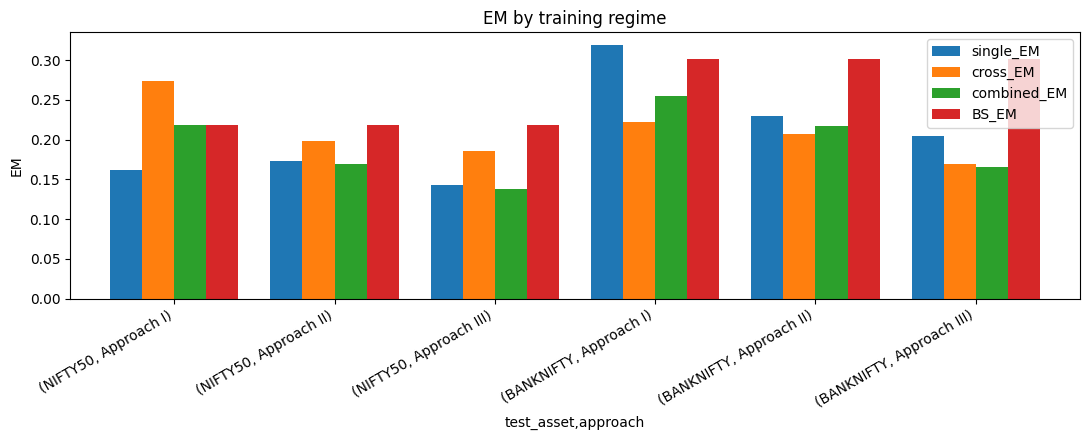


Best regime per (asset, approach):
test_asset  approach    
NIFTY50     Approach I        single_EM
            Approach II     combined_EM
            Approach III    combined_EM
BANKNIFTY   Approach I         cross_EM
            Approach II        cross_EM
            Approach III    combined_EM
Name: lowest_EM, dtype: object


In [18]:
summary_rows = []
for name in ASSETS:
    for ap in APPROACHES:
        s = single_results.loc[(name, ap)]
        row = {'test_asset': name, 'approach': ap,
               'single_EM': s['EM'], 'single_rho': s['rho']}
        if MULTI_ASSET:
            other = [a for a in ASSETS if a != name][0]
            c = cross_results.loc[(other, name, ap)]
            row.update(cross_EM=c['EM'], cross_rho=c['rho'],
                       combined_EM=combined_results.loc[(ap, name), 'EM'],
                       combined_rho=combined_results.loc[(ap, name), 'rho'])
        row.update(BS_EM=BS[name]['EM'], BS_rho=BS[name]['rho'])
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows).set_index(['test_asset', 'approach']).round(4)
print("=== EM / rho by training regime (lower is better) ===")
print(summary)

em_cols = [c for c in summary.columns if c.endswith('_EM')]
ax = summary[em_cols].plot(kind='bar', figsize=(11, 4.5), width=0.8)
ax.set_ylabel('EM'); ax.set_title('EM by training regime')
ax.axhline(0, color='black', lw=0.6)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

if MULTI_ASSET:
    print("\nBest regime per (asset, approach):")
    print(summary[em_cols].idxmin(axis=1).rename('lowest_EM'))

## Experiment 6 — Prediction-band diagnostics (Figs. 11 and 14)

Cheap add-ons that reuse the stored predictions: how often the true bin lands inside the 5-bin
predicted band, and whether the bin-midpoint price shows systematic over- or under-pricing.

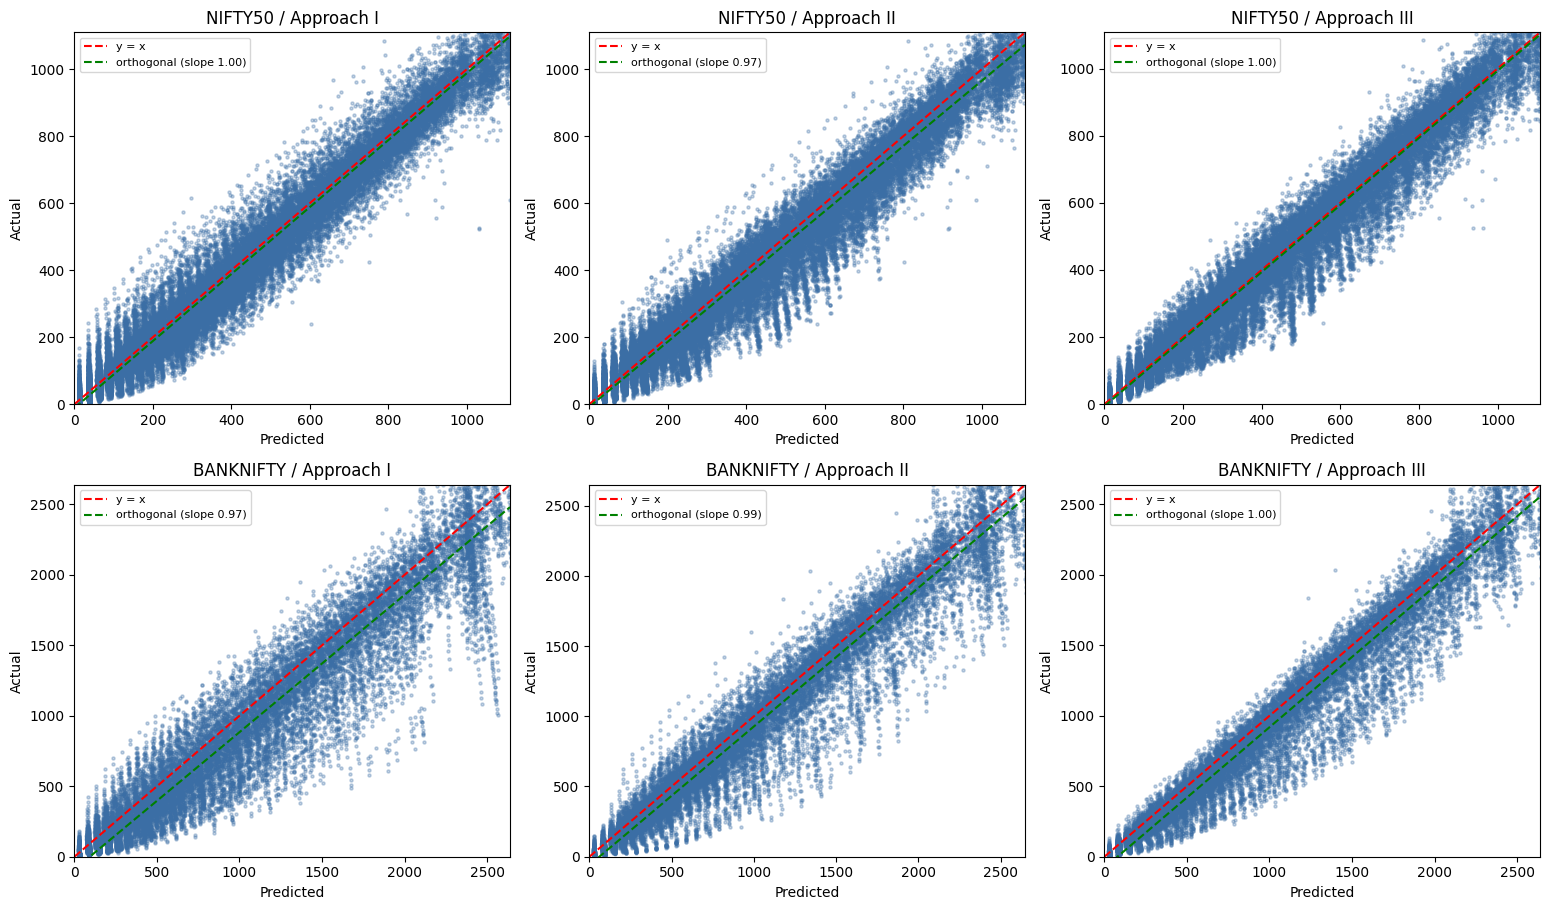

=== Band coverage and bias ===
                        P(|err|<=2)  P(|err|<=5)   q02  q98  tls_slope  mean_signed_error
asset     approach                                                                       
NIFTY50   Approach I         0.7755       0.9691  -5.0  5.0     0.9995            11.4321
          Approach II        0.7567       0.9457  -7.0  4.0     0.9732            17.6051
          Approach III       0.8185       0.9626  -6.0  4.0     0.9993             6.2837
BANKNIFTY Approach I         0.5398       0.8227 -13.0  5.0     0.9745           117.9398
          Approach II        0.6882       0.8949 -10.0  4.0     0.9872            72.6777
          Approach III       0.7359       0.9024 -10.0  3.0     0.9976            81.2949

1 - rho is the confidence the true bin lies in [P-2, P+2];
mean_signed_error near zero means no systematic over/under-pricing.


In [19]:
def orthogonal_regression(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    xm, ym = x.mean(), y.mean()
    _, _, vt = np.linalg.svd(np.column_stack([x-xm, y-ym]), full_matrices=False)
    vx, vy = vt[0]
    slope = vy/vx
    return slope, ym - slope*xm


def bin_to_price(bins, strike):
    return (np.asarray(bins, float) - 0.5) * W_BIN * np.asarray(strike, float) / 100.0


diag_rows = []
fig, axes = plt.subplots(len(ASSETS), len(APPROACHES), figsize=(5.2*len(APPROACHES), 4.6*len(ASSETS)),
                         squeeze=False)
for i, name in enumerate(ASSETS):
    d_test = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
    for j, ap in enumerate(APPROACHES):
        p = SINGLE_PRED[(name, ap)]
        err = p['y_true'].astype(float) - p['pred'].astype(float)
        pred_px = bin_to_price(p['pred'], d_test['strike'].values)
        act_px = d_test['close'].values
        slope, intercept = orthogonal_regression(pred_px, act_px)

        ax = axes[i][j]
        lim = np.nanpercentile(np.concatenate([pred_px, act_px]), 99.5)
        ax.scatter(pred_px, act_px, s=5, alpha=0.3, color='#3b6ea5')
        xs = np.linspace(0, lim, 50)
        ax.plot(xs, xs, 'r--', label='y = x')
        ax.plot(xs, slope*xs + intercept, 'g--', label=f'orthogonal (slope {slope:.2f})')
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_title(f'{name} / {ap}'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.legend(fontsize=8)

        diag_rows.append({'asset': name, 'approach': ap,
                          'P(|err|<=2)': np.mean(np.abs(err) <= 2),
                          'P(|err|<=5)': np.mean(np.abs(err) <= 5),
                          'q02': np.percentile(err, 2), 'q98': np.percentile(err, 98),
                          'tls_slope': slope, 'mean_signed_error': np.mean(pred_px - act_px)})
plt.tight_layout(); plt.show()

diagnostics = pd.DataFrame(diag_rows).set_index(['asset', 'approach']).round(4)
print("=== Band coverage and bias ===")
print(diagnostics)
print("\n1 - rho is the confidence the true bin lies in [P-2, P+2];")
print("mean_signed_error near zero means no systematic over/under-pricing.")

## Summary

In [20]:
print("=" * 80)
print("SINGLE-ASSET (Tables 4/5)"); print(single_results[['EM', 'rho', 'A']])
print("\nBLACK-SCHOLES BENCHMARK"); print(bs_table)
if MULTI_ASSET:
    print("\nCROSS-ASSET (Table 8)"); print(cross_results[['EM', 'rho']])
    print("\nCOMBINED / MULTI-ASSET (Table 9)"); print(combined_results[['EM', 'rho']])
print("\nALL REGIMES"); print(summary)
print("\nBAND COVERAGE / BIAS"); print(diagnostics[['P(|err|<=2)', 'mean_signed_error']])
print("=" * 80)

# save everything for later reuse
with pd.ExcelWriter('/content/kan_results.xlsx') as xl:
    single_results.to_excel(xl, sheet_name='single_asset')
    bs_table.to_excel(xl, sheet_name='black_scholes')
    if MULTI_ASSET:
        cross_results.to_excel(xl, sheet_name='cross_asset')
        combined_results.to_excel(xl, sheet_name='combined')
    summary.to_excel(xl, sheet_name='all_regimes')
    diagnostics.to_excel(xl, sheet_name='diagnostics')
print("results written to /content/kan_results.xlsx")

SINGLE-ASSET (Tables 4/5)
                            EM     rho       A
asset     approach                            
NIFTY50   Approach I    0.1616  0.2245  0.2706
          Approach II   0.1731  0.2433  0.2818
          Approach III  0.1435  0.1815  0.3336
BANKNIFTY Approach I    0.3190  0.4602  0.1564
          Approach II   0.2295  0.3118  0.2322
          Approach III  0.2046  0.2641  0.2640

BLACK-SCHOLES BENCHMARK
               EM     rho       A
NIFTY50    0.2185  0.3322  0.2221
BANKNIFTY  0.3011  0.4568  0.1527

CROSS-ASSET (Table 8)
                                       EM     rho
trained_on tested_on approach                    
NIFTY50    BANKNIFTY Approach I    0.2219  0.3387
                     Approach II   0.2075  0.2991
                     Approach III  0.1688  0.2291
BANKNIFTY  NIFTY50   Approach I    0.2736  0.4283
                     Approach II   0.1983  0.2739
                     Approach III  0.1862  0.2576

COMBINED / MULTI-ASSET (Table 9)
              